# 04 · Results and figures

Generates every figure, the summary table and the headline comparisons.
Headline settings: L2 (C = 1), no missingness flag, no recalibration. Everything else is a robustness check.

In [1]:
import sys, os
from pathlib import Path
# Resolve the project root so the notebook runs from either the repo root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

from IPython.display import Image, display
# make_all() builds the figures and summary table; headline() filters to the headline settings
from src.make_figures import make_all, headline

SYNTHETIC = False   # True = fake data, ONLY to check the code runs. Never report results from it.
if SYNTHETIC:
    print("WARNING: SYNTHETIC data in use. Do not interpret or report any number below.")

In [2]:
table = make_all()   # writes PNGs to results/figures and results/summary_table.csv
table

auc           brier         cal_slope             ece             mpd        
            mean     std    mean     std      mean     std    mean     std    mean     std
scenario                                                                                  
ALL 1.0   0.6239  0.0073  0.1682  0.0005    1.1244  0.2196  0.0343  0.0038  0.0819  0.0024
MAR 0.2   0.6983  0.0083  0.1523  0.0012    0.9481  0.0549  0.0428  0.0041  0.0187  0.0004
MAR 0.5   0.6712  0.0093  0.1596  0.0018    0.9519  0.1010  0.0383  0.0015  0.0446  0.0021
MAR 0.8   0.6422  0.0078  0.1657  0.0008    0.9876  0.1209  0.0363  0.0053  0.0684  0.0021
MCAR 0.2  0.7000  0.0070  0.1504  0.0013    0.9652  0.0600  0.0451  0.0057  0.0166  0.0013
MCAR 0.5  0.6713  0.0098  0.1576  0.0018    0.9403  0.0815  0.0340  0.0047  0.0406  0.0013
MCAR 0.8  0.6457  0.0096  0.1641  0.0003    1.0138  0.1165  0.0329  0.0035  0.0660  0.0019
none 0.0  0.7181  0.0059  0.1458  0.0012    0.9716  0.0440  0.0541  0.0038  0.0000  0.0000

## Figure 1 · History missingness, MCAR vs MAR

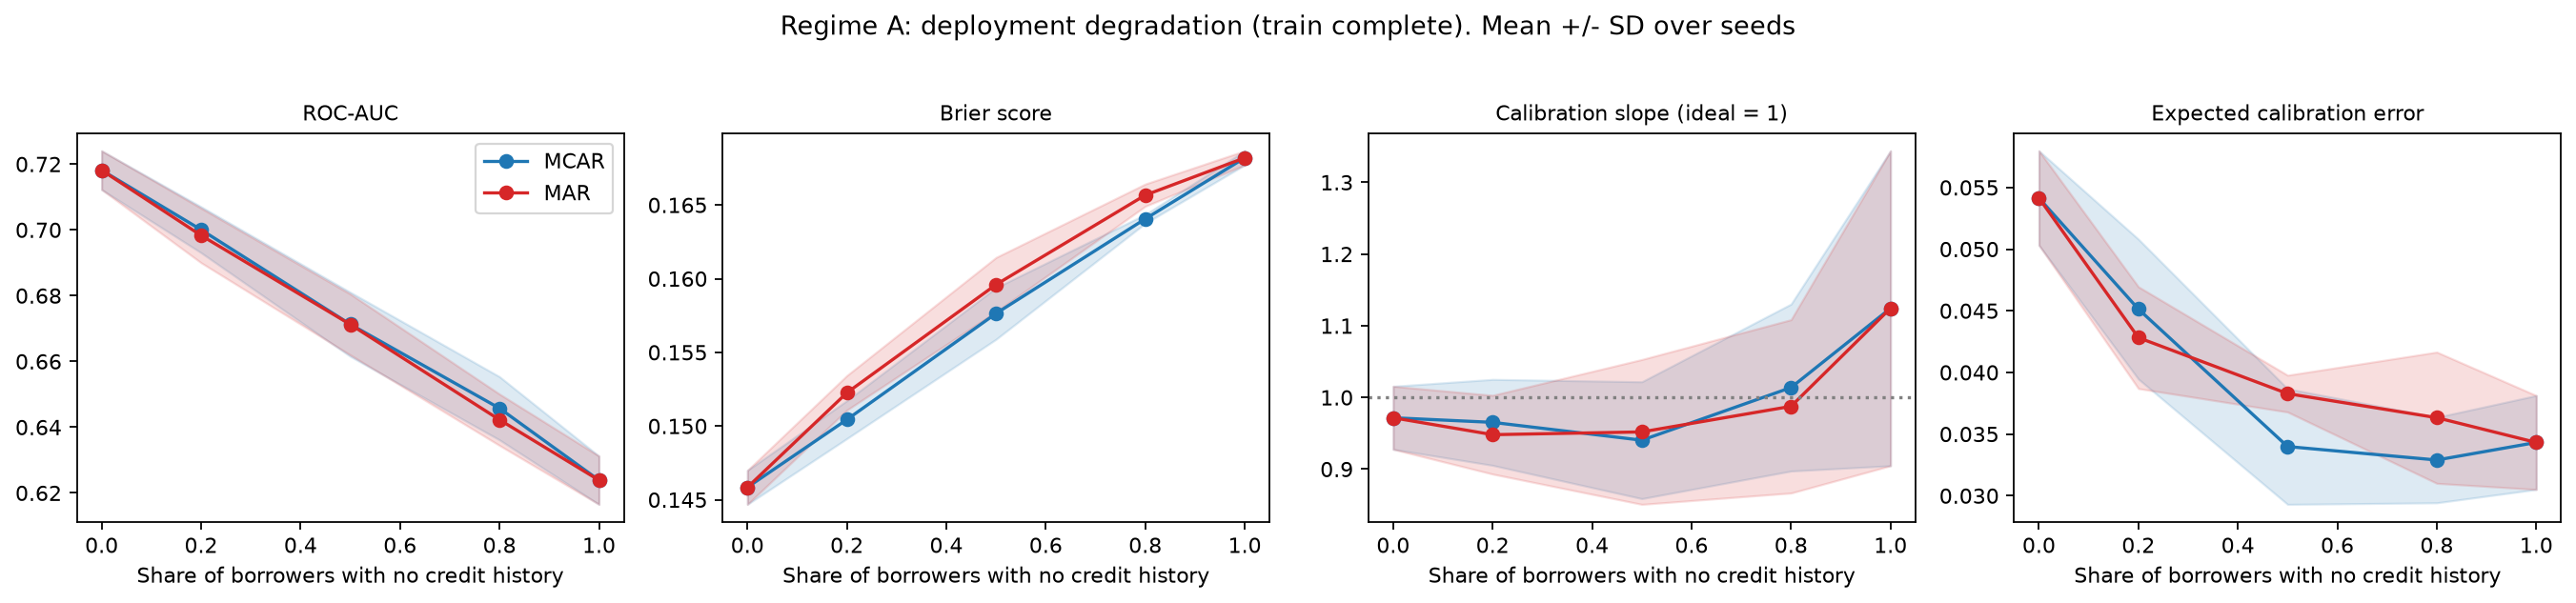

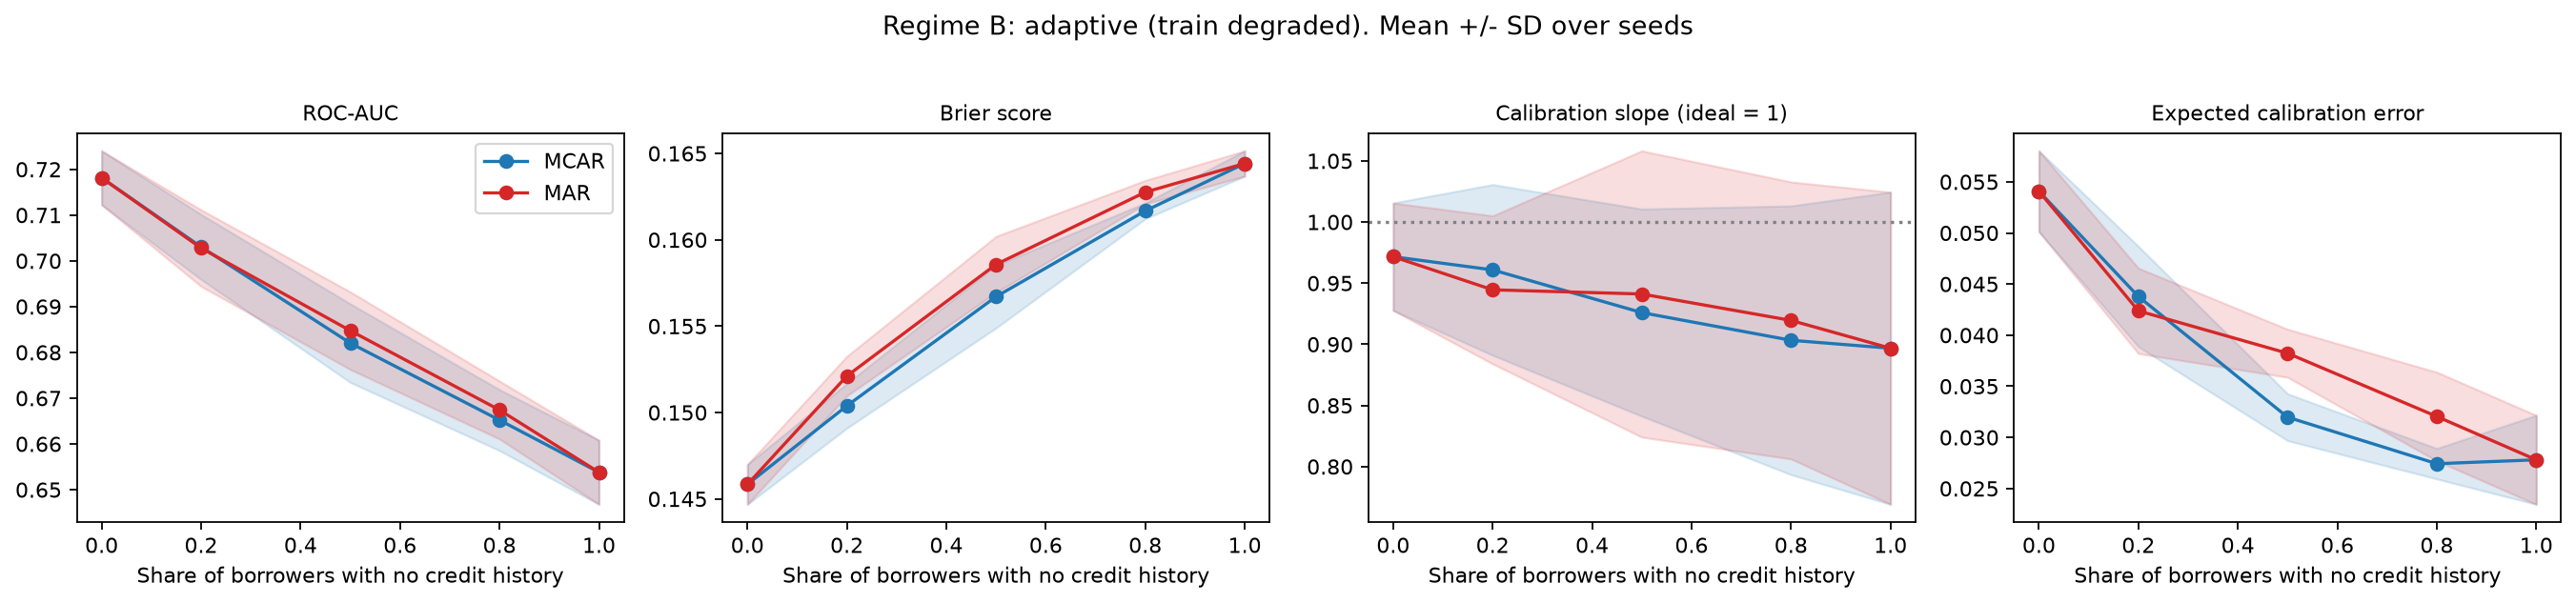

In [3]:
for f in ["fig1_history_missingness_regimeA.png", "fig1_history_missingness_regimeB.png"]:
    display(Image(filename=str(ROOT / "results" / "figures" / f)))

**Hypotheses H1 and H2.** These figures show how discrimination (AUC) and calibration change as history
missingness increases, and whether MAR differs from MCAR at the same rate. The shaded band is the seed-to-seed
spread, so gaps larger than the band are unlikely to be sampling noise. Regime A (train on complete data, deploy
on degraded data) and Regime B (train and deploy on degraded data) are shown separately.

## Figures 2 and 5 · Calibration curves and stability

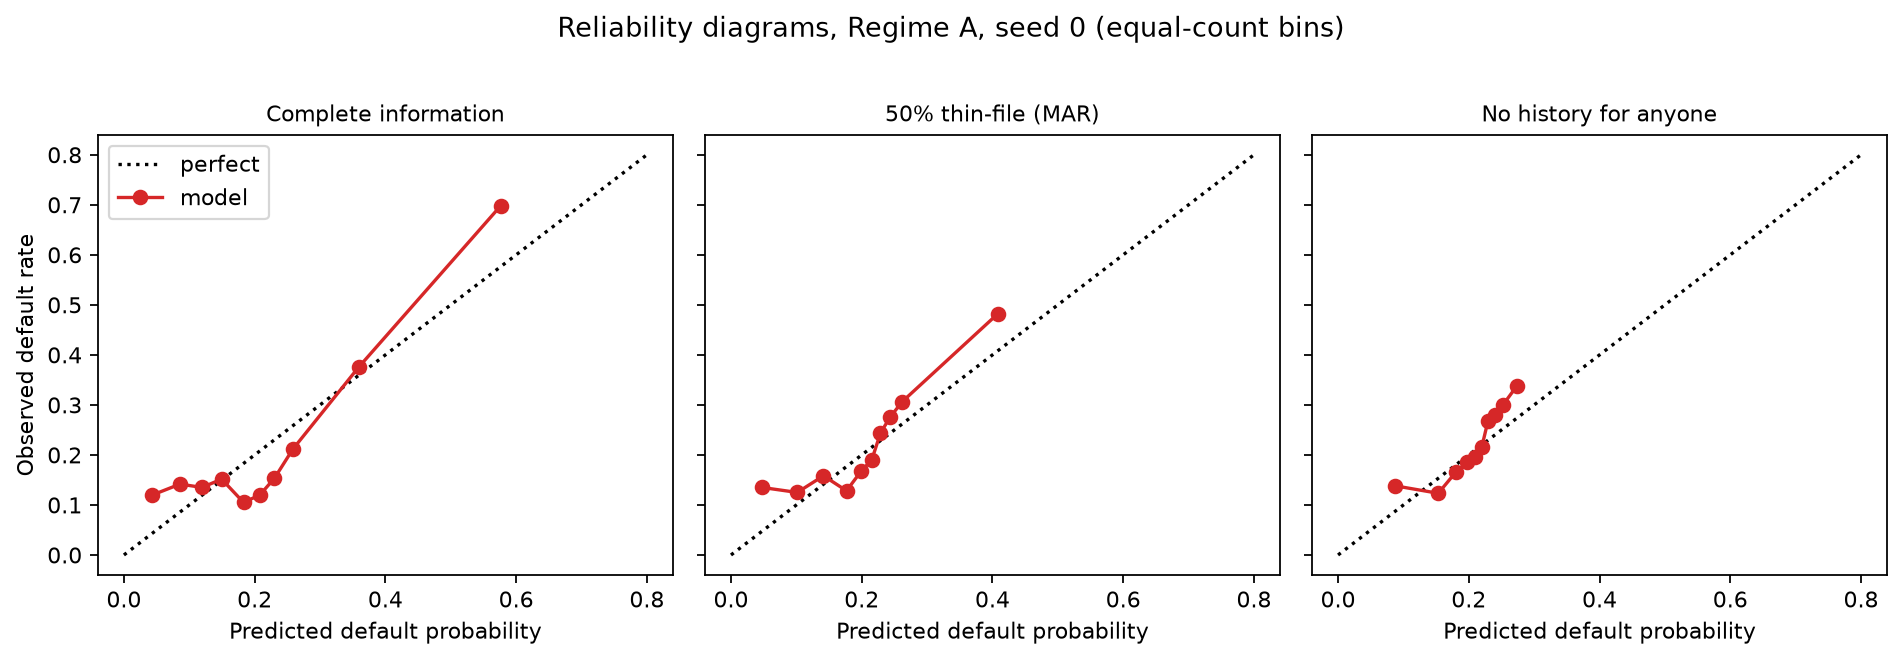

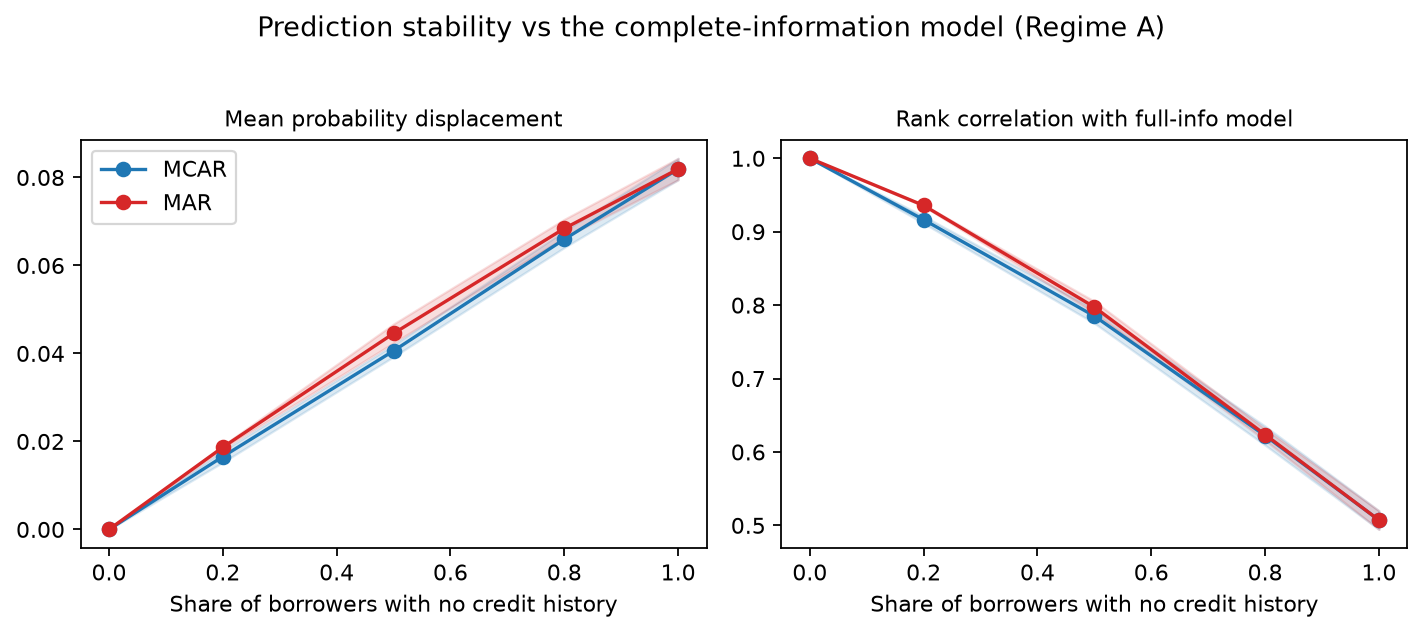

In [4]:
for f in ["fig2_calibration_curves.png", "fig5_stability.png"]:
    display(Image(filename=str(ROOT / "results" / "figures" / f)))

## Figure 3 · Sparse and noisy transactional data when history is gone (H3)

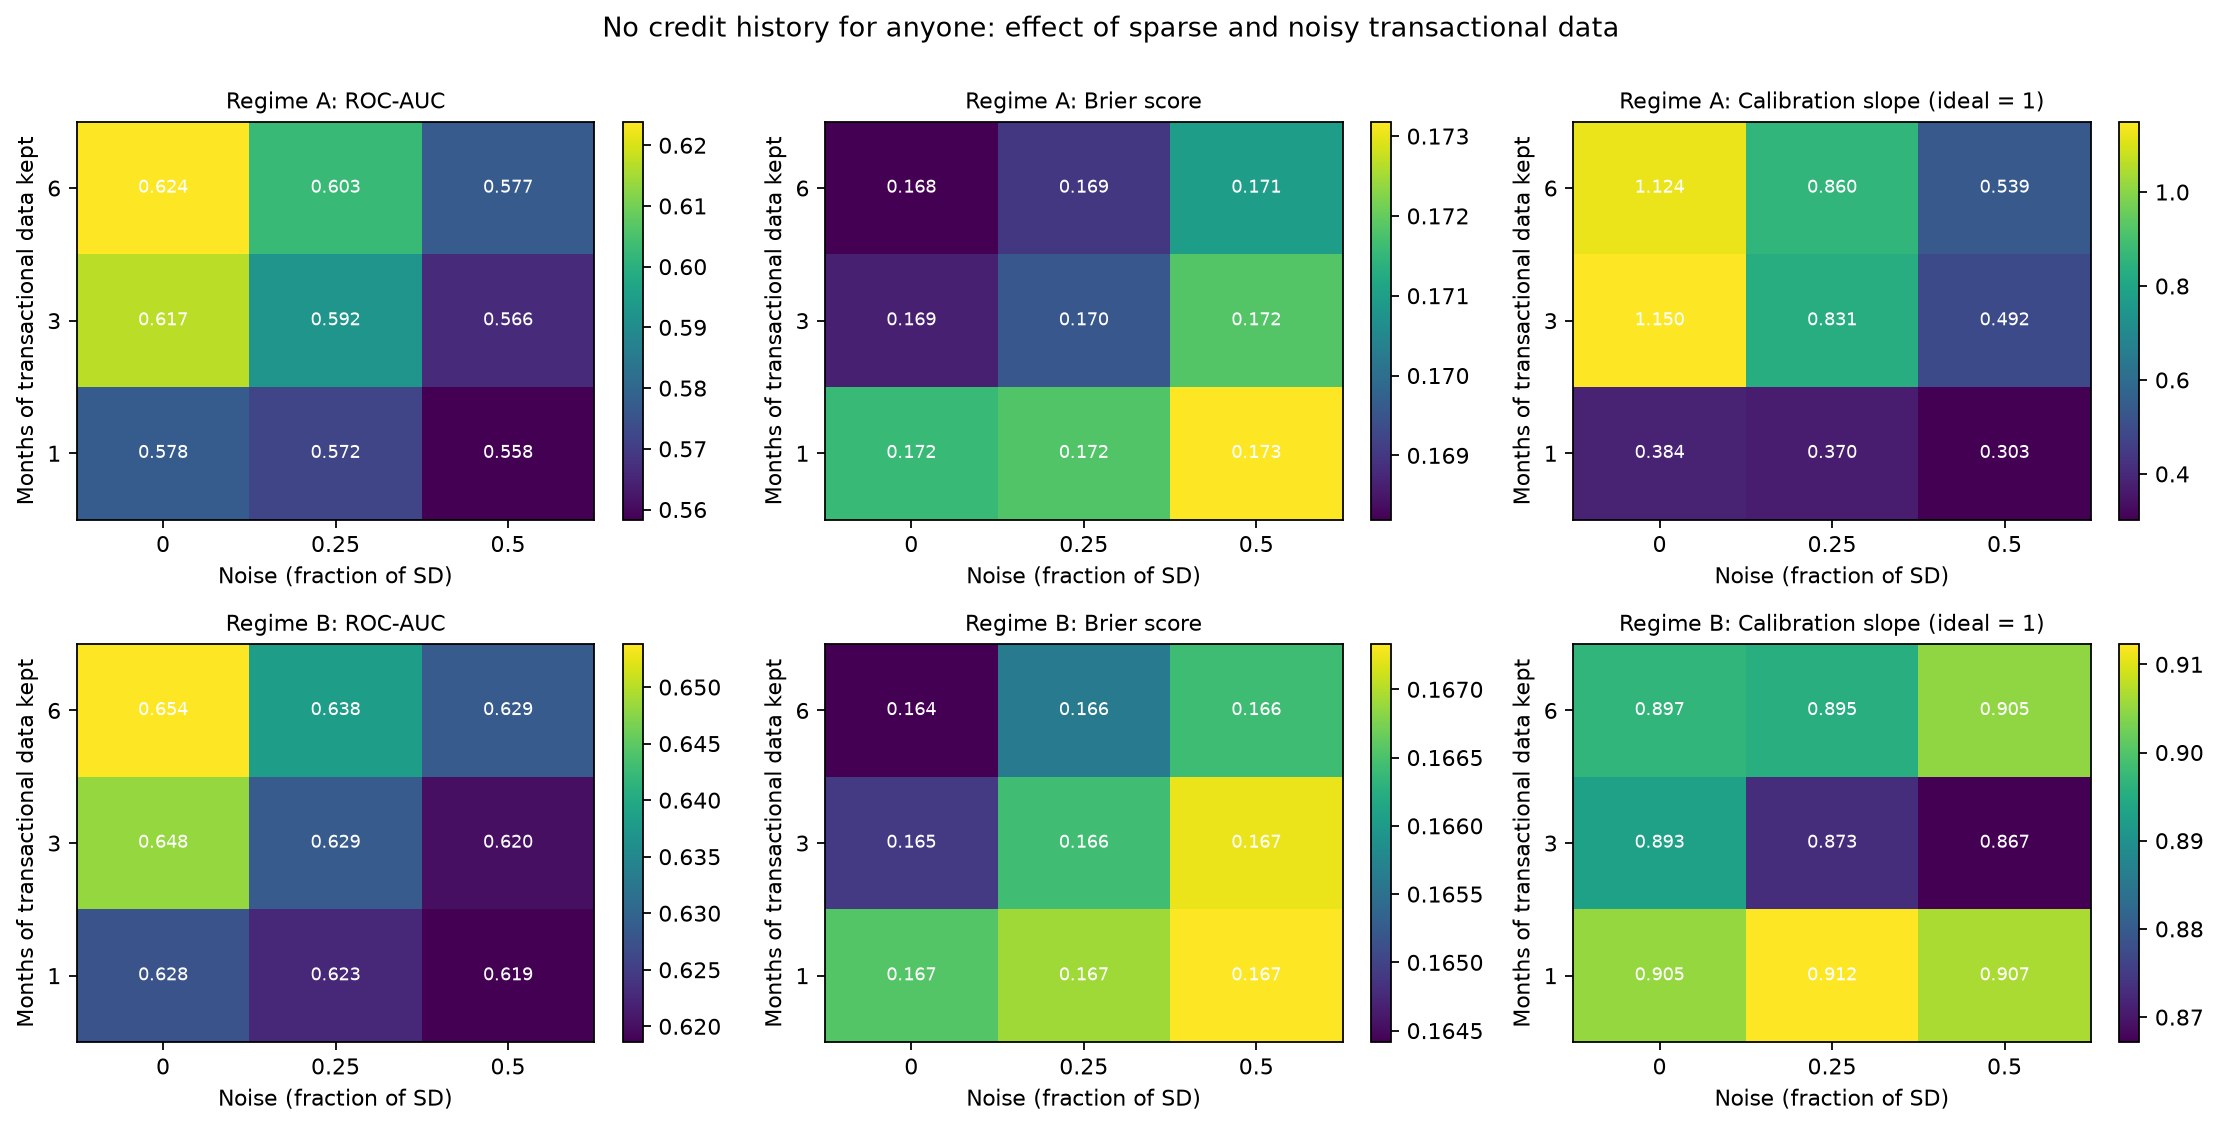

In [5]:
display(Image(filename=str(ROOT / "results" / "figures" / "fig3_sparsity_noise.png")))

## Figures 4 and 6 · Recalibration and design choices (H4)

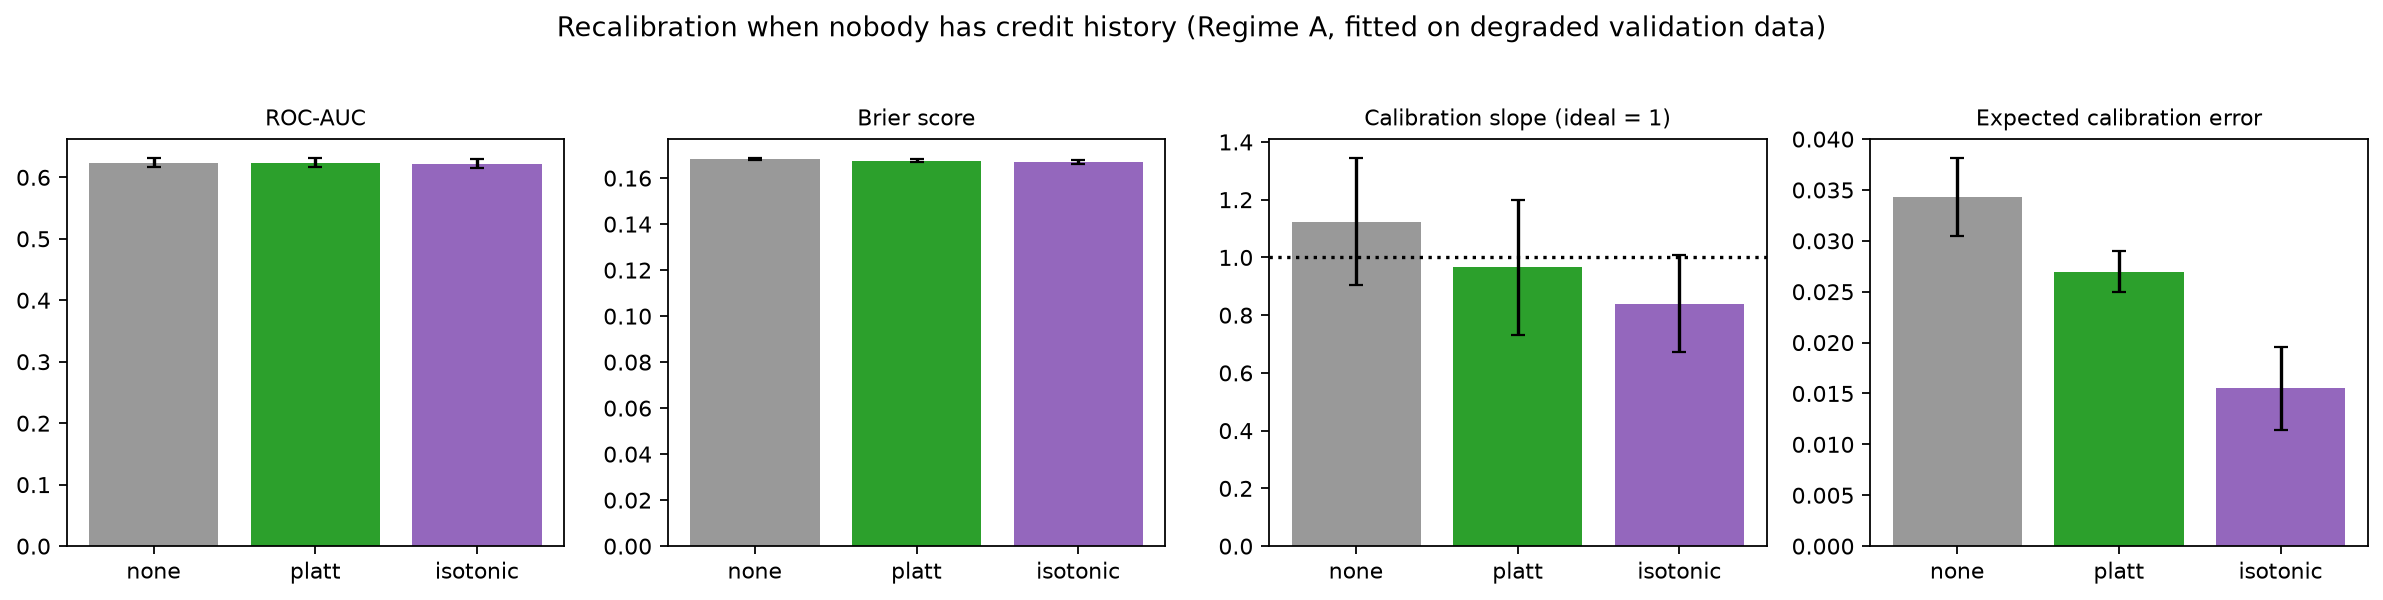

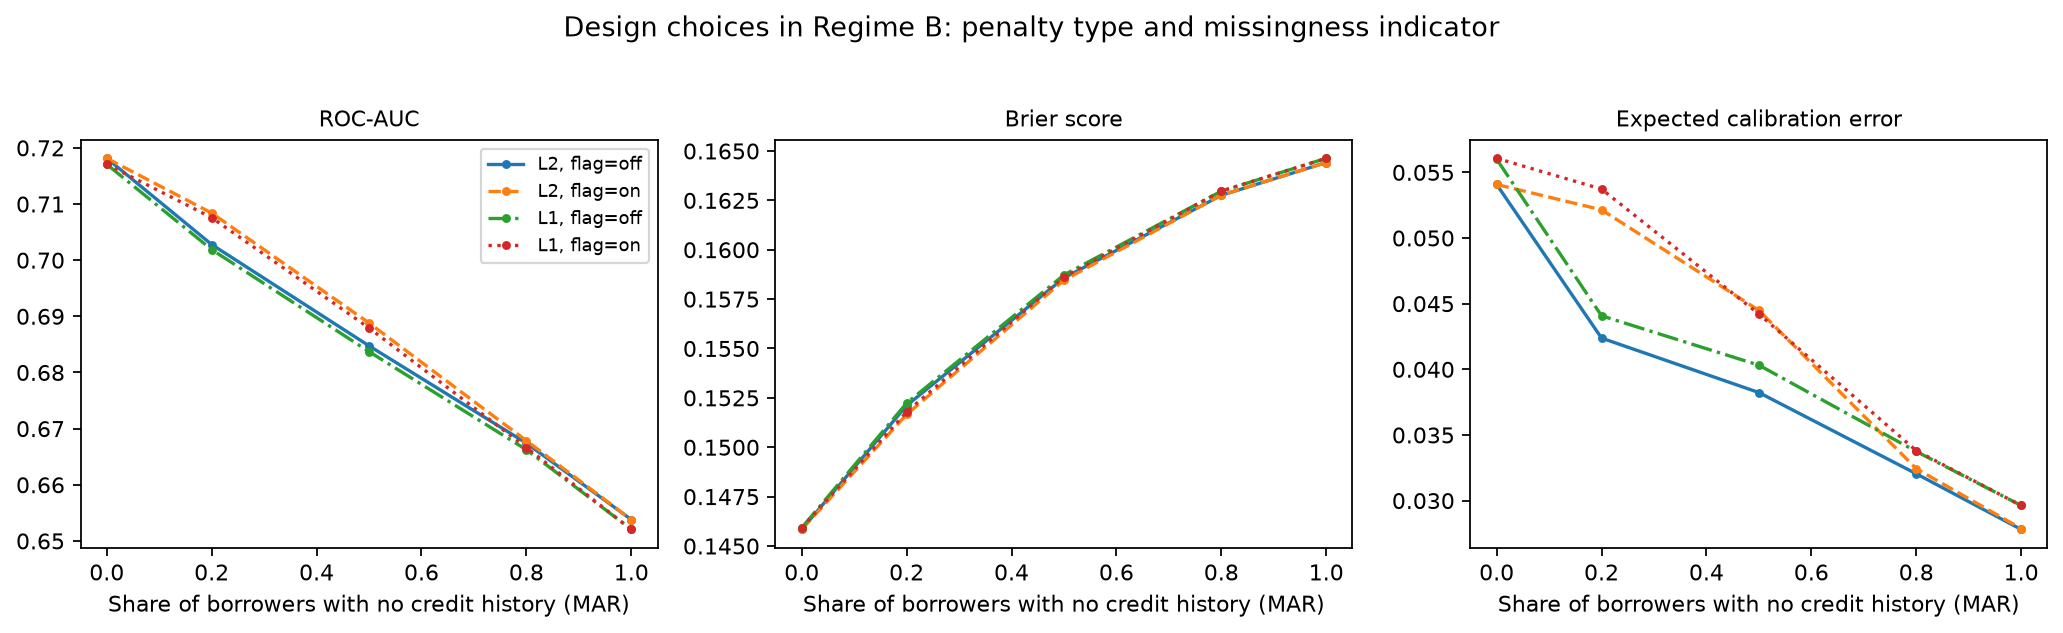

In [6]:
for f in ["fig4_recalibration.png", "fig6_design_choices.png"]:
    display(Image(filename=str(ROOT / "results" / "figures" / f)))

## Headline numbers

In [7]:
# Full results table, one row per (seed, regime, model, condition, recalibration)
res = pd.read_csv(ROOT / "results" / "results.csv")
# Regime A at the headline settings, restricted to 6 months of transactions and no added noise
A = headline(res, "A")
A = A[(A.months == 6) & (A.noise == 0)]
# Mean of each metric over seeds for one (mechanism, history rate) cell
def pick(mech, rate):
    return A[(A.mechanism == mech) & (A.hist_rate == rate)][["auc", "brier", "cal_slope", "ece", "mpd"]].mean()
# Compare complete data, 50% MCAR, 50% MAR and no history for anyone
headline_tbl = pd.DataFrame({"complete": pick("none", 0.0), "MCAR 50%": pick("MCAR", 0.5),
                             "MAR 50%": pick("MAR", 0.5), "no history": pick("ALL", 1.0)}).T
print("Regime A (train complete, deploy degraded), mean over seeds:")
headline_tbl.round(4)

Regime A (train complete, deploy degraded), mean over seeds:


,auc,brier,cal_slope,ece,mpd
complete,0.7181,0.1458,0.9716,0.0541,0.0000
MCAR 50%,0.6713,0.1576,0.9403,0.0340,0.0406
MAR 50%,0.6712,0.1596,0.9519,0.0383,0.0446
no history,0.6239,0.1682,1.1244,0.0343,0.0819


In [8]:
# Regime A with no history for anyone; compare no recalibration, Platt scaling and isotonic regression
R = res[(res.regime == "A") & (res.reg == "l2") & (~res.use_flag) & (res.months == 6) & (res.noise == 0)
        & (res.mechanism == "ALL")]
print("Recalibration, no history for anyone (Regime A):")
R.groupby("recal")[["auc", "brier", "cal_slope", "ece"]].mean().loc[["none", "platt", "isotonic"]].round(4)

Recalibration, no history for anyone (Regime A):


,auc,brier,cal_slope,ece
recal,,,,
none,0.6239,0.1682,1.1244,0.0343
platt,0.6239,0.1675,0.9652,0.0270
isotonic,0.6220,0.1671,0.8404,0.0155


## Hypotheses and findings

Hypotheses tested:

- **H1** Calibration degrades before AUC does.
- **H2** MAR hurts differently from MCAR at the same rate.
- **H3** Sparsity and noise erode what transactional data can compensate for.
- **H4** Recalibration repairs probabilities but cannot restore discrimination.

### Findings

All numbers are means over 5 seeds (headline settings: L2, C = 1, no missingness flag, no recalibration); bands in
the figures are ±1 SD across seeds. With only 5 seeds, differences smaller than the SD are treated as noise.

| Hypothesis | Verdict | Main evidence |
|---|---|---|
| **H1** Calibration degrades before AUC | Not supported | AUC and Brier degrade steadily; calibration slope and ECE show no early deterioration (Figure 1) |
| **H2** MAR differs from MCAR | Mostly not supported | AUC and calibration are indistinguishable; Brier and probability displacement are slightly worse under MAR |
| **H3** Sparsity and noise erode transactional data | Supported | Most of the loss comes from keeping only 1 month or adding heavy noise (Figure 3) |
| **H4** Recalibration repairs probabilities, not discrimination | Supported, with caveats | ECE falls and AUC does not recover (Figure 4) |

**H1: discrimination degrades first, not calibration.** In Regime A, AUC falls from 0.718 with complete data to
0.671 at 50% missingness and 0.624 with no history, and Brier score rises in step (0.146, 0.158, 0.168). Calibration
slope shows no comparable early deterioration: it stays between 0.94 and 1.01 up to 80% missingness and reaches only
1.12 with no history, with a seed SD of 0.04-0.22. ECE actually *falls* (0.054 to 0.034). Regime B gives the same
picture (slope 0.97 to 0.90, ECE 0.054 to 0.028, wide bands). The reliability diagrams (Figure 2, seed 0) show why:
the complete-information model's largest errors sit in the tails (about 0.04 predicted against about 0.12 observed in
the lowest bin), and as history disappears predictions are squeezed towards the 22% base rate (the highest bin is
about 0.27 with no history), leaving fewer extreme predictions to get wrong. A lower ECE here reflects less
informative predictions, not more reliable ones.

**H2: MAR and MCAR behave almost the same.** At 20%, 50% and 80% missingness, AUC differs by at most 0.004 (for
example 0.671 under both at 50%), well inside the seed SD of 0.007-0.010. Calibration slope and ECE overlap
throughout. MAR is slightly worse on Brier score (by about 0.002 at each rate) and on mean probability displacement
(0.045 against 0.041 at 50%), differences about the size of the seed SD, so the evidence for a MAR effect is weak
even though the direction is consistent. This is notable because notebook 02 shows that MAR hides a very different
group: lower credit limits and higher default rates. One possible explanation, which these experiments do not test,
is that credit limit is already a model input, so hiding history for low-limit borrowers removes less than it
appears to. Rank agreement with the complete-information model (Figure 5) is also similar under both mechanisms.

**H3: sparsity and noise matter, mostly at the extremes.** With no history for anyone, going from 6 months of
transactional data to 3 costs little (AUC 0.624 to 0.617 in Regime A, 0.654 to 0.648 in Regime B). Keeping only 1
month costs much more (0.578 and 0.628), as does noise at 0.5 SD (0.577 and 0.629). The worst corner, 1 month with
noise 0.5, gives 0.558 in Regime A and 0.619 in Regime B. The Regime B figure is close to the 0.613 of the
profile-only model from notebook 01, so almost all of what transactional data add over profile data is gone.
Calibration responds differently by regime. When the model was trained on clean data (Regime A), calibration slope
collapses as the inputs degrade (1.12 with no noise, 0.86 at noise 0.25, 0.54 at noise 0.5, and 0.38 with 1 month
of data), meaning predictions are far more extreme than outcomes justify. When the model is trained on degraded data
(Regime B), the slope stays at 0.87-0.91 throughout. Brier score barely moves in either regime (0.168 to 0.173 in A,
0.164 to 0.167 in B), so it hides this calibration damage.

**H4: recalibration fixes probabilities, not ranking.** With no history for anyone (Regime A), AUC is unchanged by
Platt scaling (0.624) and slightly lower under isotonic regression (0.622). ECE falls from 0.034 to 0.027 (Platt)
and 0.016 (isotonic), and Brier improves only marginally (0.1682 to 0.1675 and 0.1671). The calibration slope moves
from 1.12 to 0.97 with Platt, but to 0.84 with isotonic, so the method with the lowest ECE overshoots on slope.
Seed SDs on the slope are large (about 0.2), so the slope changes should be read cautiously. Recalibration was
evaluated only in this single setting, not under sparse or noisy transactional data, where Figure 3 shows the
calibration damage is largest.

**Design choices.** In Regime B under MAR, L1 and L2 penalties give nearly identical AUC and Brier score. Adding a
missingness flag raises AUC slightly (roughly 0.003-0.005 at 20-50% missingness) but gives a higher ECE at those
rates, so the headline settings without the flag are not clearly worse.

**Regime A versus Regime B.** Retraining on degraded data recovers some discrimination (no-history AUC 0.654 in
Regime B against 0.624 in Regime A) and, in the sparse and noisy settings, keeps calibration stable.

**Results that cut against expectations.**
- ECE improves as information is lost, the opposite of what H1 anticipated (see the explanation under H1).
- Under Regime A, the calibration slope with no history rises above 1 (1.12) and only falls below 1 when
  transactional data are also sparse or noisy.
- MAR, despite hiding a very different group of borrowers, changes aggregate performance very little.

### What this study cannot tell us

- The data are Taiwanese consumer credit records, so the findings may not transfer to other markets or products.
- Missingness is simulated rather than observed; real thin-file borrowers may differ in ways the simulation does not capture.
- Only MCAR and MAR (driven by credit limit) are studied; missingness that depends on unobserved values is not.
- Billing and payment amounts serve as a proxy for alternative transactional data.
- Results come from 5 random splits, so small differences between conditions cannot be separated from seed-to-seed variation.
- The results are descriptive comparisons from simulation; no causal claims are made.